# Practice Work #8
## Topic: Plotting Data using Matplotlib
## Group: IT2-2404SE
## Full Name: Daniil Kalts

---

### Exercise 1 – Line Plot of Tickets Sold
Plot the following data using a line plot:

| Day | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|
| Tickets sold | 2000 | 2800 | 3000 | 2500 | 2300 | 2500 | 1000 |

**Tasks:**
- a. Before displaying the plot, show "Monday, Tuesday, Wednesday, Thursday, Friday, Saturday, Sunday" in place of Day 1, 2, 3, 4, 5, 6, 7.
- b. Change the color of the line to `'Magenta'`.

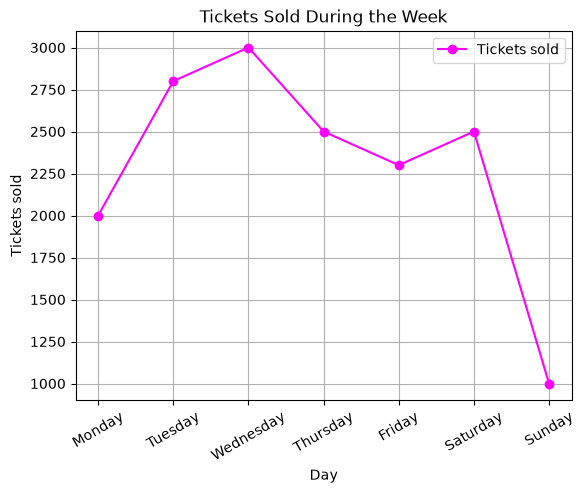

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

tickets = pd.DataFrame({
    'Day': [1, 2, 3, 4, 5, 6, 7],
    'Tickets sold': [2000, 2800, 3000, 2500, 2300, 2500, 1000]
})

week_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

tickets.plot(kind='line', x='Day', y='Tickets sold', color='magenta', marker='o')

plt.xticks(tickets['Day'], week_days, rotation=30)
plt.title('Tickets Sold During the Week')
plt.xlabel('Day')
plt.ylabel('Tickets sold')
plt.grid(True)

plt.show()

### Exercise 2 – Courses Offered by Universities
Collect data about 3–4 universities and the number of courses they run for **Science**, **Commerce** and **Humanities**, store it in a CSV file and present it using a bar plot.

**Tasks:**
- a. Create a DataFrame with the columns `'University'`, `'Science'`, `'Commerce'` and `'Humanities'`.
- b. Save it to the file `universities.csv`.
- c. Read the CSV file back and present the data with a bar plot.

            University  Science  Commerce  Humanities
0                 IITU       24         4           4
1                 KBTU       18        10           0
2                 AITU       11         4           2
3  Satbayev University       67         3           1



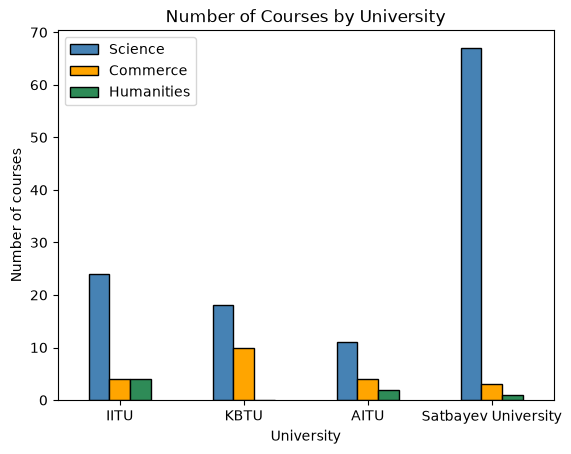

In [2]:
universities = pd.DataFrame({
    'University': ['IITU', 'KBTU', 'AITU', 'Satbayev University'],
    'Science': [24, 18, 11, 67],
    'Commerce': [4, 10, 4, 3],
    'Humanities': [4, 0, 2, 1]
})

universities.to_csv('universities.csv', index=False)

df = pd.read_csv('universities.csv')
print(df, end='\n\n')

df.plot(kind='bar', x='University', color=['steelblue', 'orange', 'seagreen'],
        edgecolor='black', title='Number of Courses by University')
plt.ylabel('Number of courses')
plt.xticks(rotation=0)

plt.show()

**Data source:** the number of **bachelor's educational programs** listed by each university (November 2026):
- **IITU**: 32 programs, [iitu.edu.kz/en/applicants/bachelor](https://iitu.edu.kz/en/applicants/bachelor/)
- **KBTU**: 28 programs, [univision.kz](https://univision.kz/univ/63-kazahstansko-britanskiy-tehnicheskiy-universitet/edu-program) (the official KBTU program page was unavailable)
- **AITU**: 17 programs, [astanait.edu.kz/en/bachelor](https://astanait.edu.kz/en/bachelor/)
- **Satbayev University**: 74 programs for 2026–2027, [official.satbayev.university/kk/programs](https://official.satbayev.university/kk/programs)

**How programs were grouped**, using the Kazakhstan program code (6Bxx):
- **Science**: natural sciences, ICT, engineering, agriculture (6B05, 6B06, 6B07, 6B08)
- **Commerce**: business, management, economics, finance (6B04)
- **Humanities**: arts, design, journalism, law (6B02, 6B03, and law programs)

AITU's page has no codes, so its programs were grouped by name (Digital Journalism and Digital Jurisprudence → Humanities; Digital Public Administration, AI Business, IT Management, IT Entrepreneurship → Commerce). Satbayev's 3 service programs (6B11: transport services, labor safety, digital logistics) fit none of the three groups and are not counted.

### Exercise 3 – GDP Growth Rate
Fill in the data based on the image ("GDP growth rate of a Country"). Create a DataFrame with the years **Year** and the corresponding GDP values **GDP**, then write the `plot()` call that builds this chart.

**Tasks:**
- a. Create a DataFrame with the columns `'Year'` and `'GDP'`.
- b. Use `plot()` to build the line chart with the title "GDP growth rate of a Country".

    Year  GDP
0  Year1  2.6
1  Year2  2.3
2  Year3  2.9
3  Year4  3.0
4  Year5  3.1



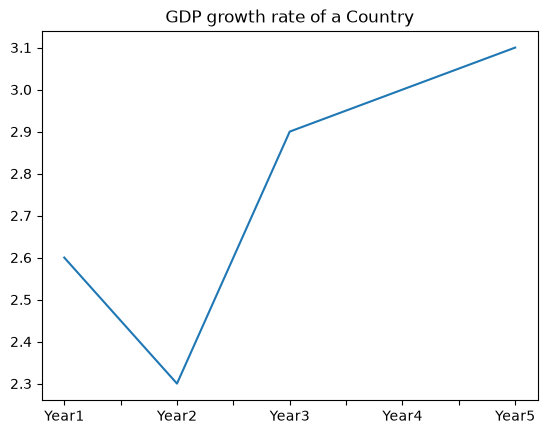

In [3]:
gdp = pd.DataFrame({
    'Year': ['Year1', 'Year2', 'Year3', 'Year4', 'Year5'],
    'GDP': [2.6, 2.3, 2.9, 3.0, 3.1]
})

print(gdp, end='\n\n')

gdp.plot(kind='line', x='Year', y='GDP', title='GDP growth rate of a Country', legend=False)
plt.xlabel('')

plt.show()

### Exercise 4 – Sales Dashboard
Use the **sales_data** dataset below and create one dashboard with four visualizations (no line or bar plots):
1. Scatter plot
2. Histogram
3. Box plot
4. Heatmap

**Business scenario.** A company wants to understand:
- whether advertising is related to sales;
- how profit is distributed;
- whether profit differs between products;
- how the numerical variables are correlated.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

rng = np.random.default_rng(42)
n = 200

sales_data = pd.DataFrame({
    "date": pd.date_range(start="2025-01-01", periods=n, freq="D"),
    "region": rng.choice(["North", "South", "East", "West"], size=n),
    "product": rng.choice(["Laptop", "Tablet", "Phone", "Monitor"], size=n),
    "advertising": rng.normal(500, 120, size=n).round(2),
    "units_sold": rng.poisson(20, size=n),
    "customer_rating": rng.normal(4.0, 0.5, size=n).clip(1, 5).round(1)
})

product_price = {
    "Laptop": 1200,
    "Tablet": 600,
    "Phone": 800,
    "Monitor": 400
}

sales_data["price"] = sales_data["product"].map(product_price)

sales_data["sales"] = (
    sales_data["units_sold"] * sales_data["price"]
    + sales_data["advertising"] * 3
    + rng.normal(0, 1500, size=n)
).round(2)

sales_data["expenses"] = (
    sales_data["sales"] * rng.uniform(0.55, 0.85, size=n)
).round(2)

sales_data["profit"] = (
    sales_data["sales"] - sales_data["expenses"]
).round(2)

# Add several unusual observations
sales_data.loc[[15, 75, 150], "sales"] *= 2.5
sales_data.loc[[15, 75, 150], "profit"] *= 2.5

sales_data.head()

,date,region,product,advertising,units_sold,customer_rating,price,sales,expenses,profit
0,2025-01-01,North,Tablet,577.20,13,4.3,600,8989.69,6347.95,2641.74
1,2025-01-02,West,Monitor,452.65,22,4.7,400,10686.00,7363.75,3322.25
2,2025-01-03,East,Tablet,499.39,21,3.1,600,12615.23,9550.21,3065.02
3,2025-01-04,South,Phone,480.39,16,3.8,800,14916.65,8935.33,5981.32
4,2025-01-05,South,Tablet,540.51,28,3.6,600,18426.19,13828.84,4597.35


### Exercise 4. Task 1 – Prepare the Data
Calculate the correlation matrix of the numeric columns.

In [5]:
numeric_columns = [
    "advertising",
    "units_sold",
    "price",
    "sales",
    "expenses",
    "profit",
    "customer_rating"
]

correlation_matrix = sales_data[numeric_columns].corr()
correlation_matrix.round(2)

,advertising,units_sold,price,sales,expenses,profit,customer_rating
advertising,1.00,-0.07,-0.02,-0.02,-0.02,0.03,-0.05
units_sold,-0.07,1.00,-0.03,0.50,0.47,0.41,-0.05
price,-0.02,-0.03,1.00,0.71,0.78,0.59,0.02
sales,-0.02,0.50,0.71,1.00,0.88,0.79,0.02
expenses,-0.02,0.47,0.78,0.88,1.00,0.57,-0.03
profit,0.03,0.41,0.59,0.79,0.57,1.00,0.01
customer_rating,-0.05,-0.05,0.02,0.02,-0.03,0.01,1.00


### Exercise 4. Task 2 & 3 – Create and Complete the Four-Part Dashboard
Create a 2 × 2 figure:
- A. **Scatter plot** of advertising and sales in `axes[0, 0]`.
- B. **Histogram** of the profit distribution in `axes[0, 1]`.
- C. **Box plot** of profit by product in `axes[1, 0]`.
- D. **Heatmap** of the correlations in `axes[1, 1]`.

Add a main title and improve the spacing.

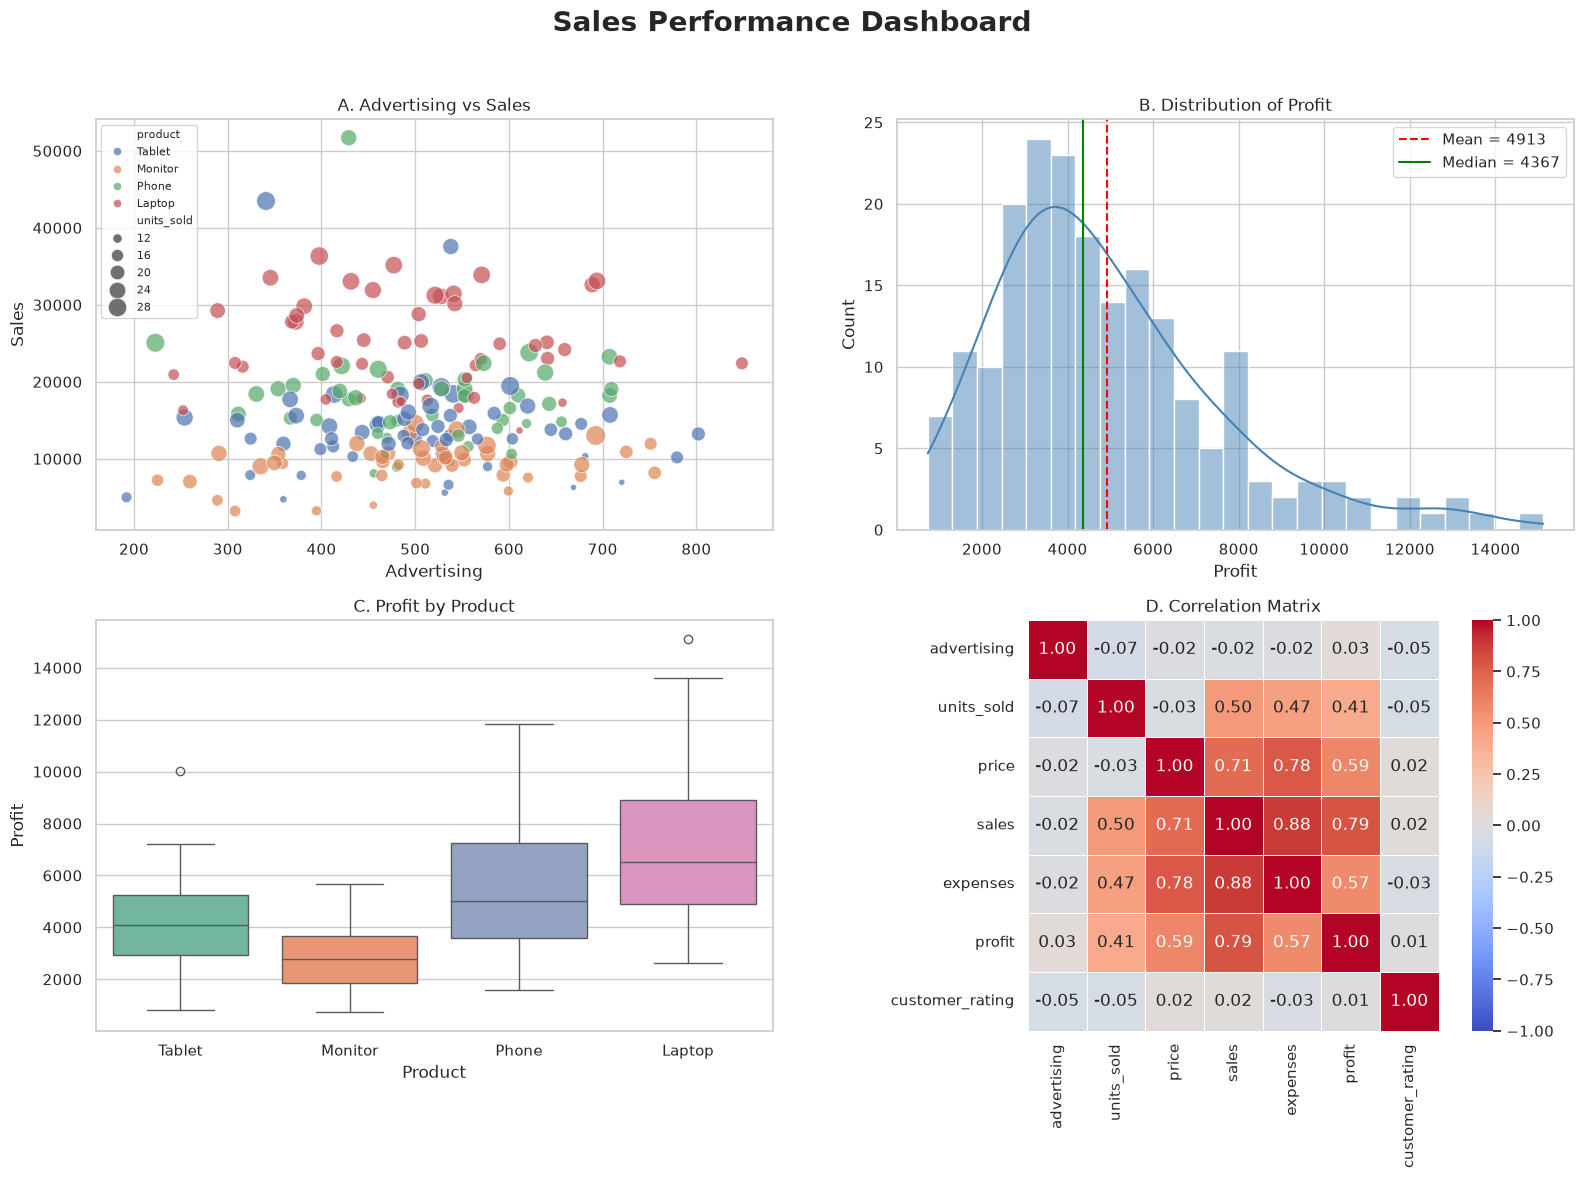

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# A. Scatter plot: advertising and sales
sns.scatterplot(data=sales_data, x="advertising", y="sales", hue="product",
                size="units_sold", sizes=(20, 200), alpha=0.7, ax=axes[0, 0])
axes[0, 0].set_title("A. Advertising vs Sales")
axes[0, 0].set_xlabel("Advertising")
axes[0, 0].set_ylabel("Sales")
axes[0, 0].legend(fontsize=8, loc="upper left")

# B. Histogram: distribution of profit
sns.histplot(data=sales_data, x="profit", bins=25, kde=True, color="steelblue", ax=axes[0, 1])
axes[0, 1].axvline(sales_data["profit"].mean(), color="red", linestyle="--",
                   label=f"Mean = {sales_data['profit'].mean():.0f}")
axes[0, 1].axvline(sales_data["profit"].median(), color="green", linestyle="-",
                   label=f"Median = {sales_data['profit'].median():.0f}")
axes[0, 1].set_title("B. Distribution of Profit")
axes[0, 1].set_xlabel("Profit")
axes[0, 1].set_ylabel("Count")
axes[0, 1].legend()

# C. Box plot: profit by product
sns.boxplot(data=sales_data, x="product", y="profit", hue="product", palette="Set2", ax=axes[1, 0])
axes[1, 0].set_title("C. Profit by Product")
axes[1, 0].set_xlabel("Product")
axes[1, 0].set_ylabel("Profit")

# D. Heatmap: correlations
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=axes[1, 1])
axes[1, 1].set_title("D. Correlation Matrix")

fig.suptitle("Sales Performance Dashboard", fontsize=20, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [7]:
print("Median sales by product:")
print(sales_data.groupby("product")["sales"].median().sort_values(ascending=False), end="\n\n")

print("Unusual observations:")
print(sales_data.loc[[15, 75, 150], ["product", "advertising", "sales", "profit"]], end="\n\n")

print("Profit mean:", sales_data["profit"].mean().round(2))
print("Profit median:", sales_data["profit"].median())
print("Profit skewness:", round(sales_data["profit"].skew(), 2), end="\n\n")

print("Profit by product:")
print(sales_data.groupby("product")["profit"].agg(["median", "std"]).round(2))

Median sales by product:
product
Laptop     24186.580
Phone      18038.675
Tablet     13248.280
Monitor     9557.550
Name: sales, dtype: float64

Unusual observations:
    product  advertising      sales     profit
15   Tablet       340.83  43484.275   7209.875
75   Tablet       537.98  37572.400  10006.800
150   Phone       429.07  51700.825  11840.950

Profit mean: 4912.92
Profit median: 4367.21
Profit skewness: 1.18

Profit by product:
          median      std
product                  
Laptop   6508.28  3007.24
Monitor  2787.98  1170.44
Phone    5017.96  2279.60
Tablet   4080.90  1746.91


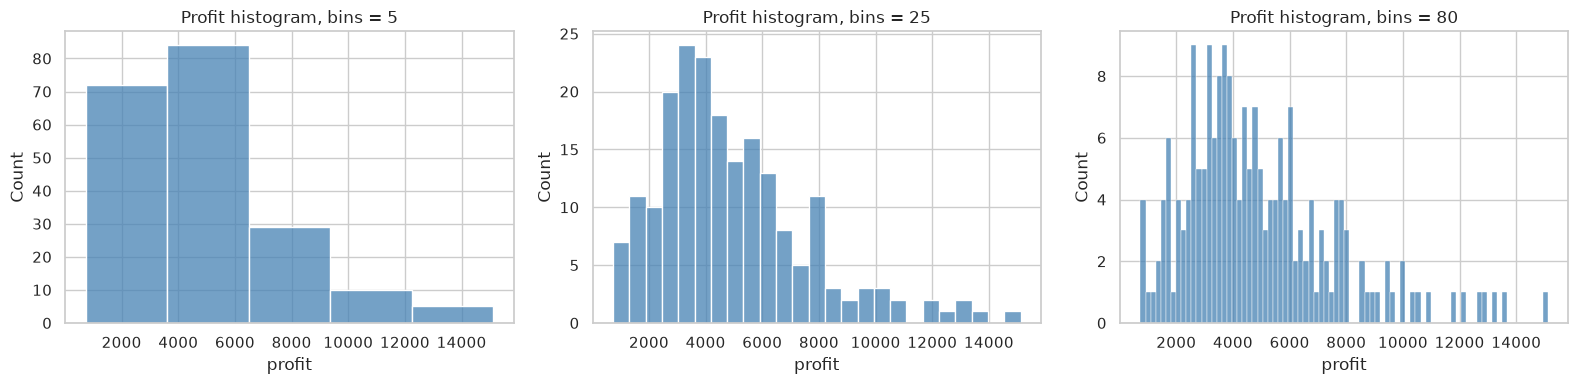

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, bins in zip(axes, [5, 25, 80]):
    sns.histplot(data=sales_data, x="profit", bins=bins, color="steelblue", ax=ax)
    ax.set_title(f"Profit histogram, bins = {bins}")
plt.tight_layout()
plt.show()

**Answers:**

**A. Scatter plot (advertising vs sales)**
- There is practically **no relationship**. The points form a flat cloud, and the correlation is about **-0.02**, so advertising doesn't explain sales in this data.
- **Laptop** generally has the highest sales (median ≈ 24,187), followed by Phone, Tablet and Monitor. This follows the product price.
- Yes. Three points stand far above the rest: rows **15** (Tablet, ≈ 43,484), **75** (Tablet, ≈ 37,572) and **150** (Phone, ≈ 51,701). These are the rows multiplied by 2.5.
- The point size shows **units_sold**: bigger points mean more units sold that day.

**B. Histogram (profit distribution)**
- The distribution is **right-skewed** (skewness ≈ 1.18). Most days are between 2,000 and 7,000, with a long tail to the right.
- They are close but not equal: mean ≈ **4,913** and median ≈ **4,367**. The mean is higher because the right tail pulls it up.
- Yes. Values above about 11,000 (up to ≈ 15,116) are possible extreme values.
- With few bins (5) the shape is too rough and hides details. With many bins (80) it gets noisy and shows random gaps. A medium number (≈ 25) shows the shape best.

**C. Box plot (profit by product)**
- **Laptop** has the highest median profit (≈ 6,508).
- **Laptop** also has the greatest variability (largest box and whiskers, std ≈ 3,007).
- **Laptop** and **Tablet** each have one point outside the whiskers (Tablet: row 75, ≈ 10,007).
- The **box** covers the middle 50% of the data (Q1 to Q3, the IQR). The **center line** is the median. The **whiskers** reach the furthest points within 1.5 × IQR of the box. **Individual points** are values outside the whiskers, i.e. possible outliers.

**D. Heatmap (correlations)**
- The strongest positive correlations are **sales–expenses (0.88)**, **sales–profit (0.79)** and **price–expenses (0.78)**. Expenses and profit are calculated from sales, so this is expected.
- **advertising** and **customer_rating** have weak relationships (|r| < 0.1) with every other variable.
- No, customer rating is **not** related to sales (r ≈ 0.02).
- The diagonal is 1 because every variable is perfectly correlated with itself.
- No. Correlation only measures how strongly two variables move together. It doesn't show that one causes the other: the link may come from a third variable, from how the data was built (e.g. profit = sales − expenses), or from chance.